# TP7 — Plongements lexicaux en pratique (word embeddings)
**TALN · Chapitre 4 (partie 2) · Séance 15**

Au cours (séance 14), vous avez vu l'**hypothèse distributionnelle**, **Word2Vec** (CBOW et Skip-gram), **GloVe** et **FastText**.
Dans ce TP, vous allez les utiliser sur de vrais textes :

| Partie | Ce que vous allez faire |
|---|---|
| 1 | Préparer le corpus : lire les avis, les découper en mots |
| 2 | Entraîner **Word2Vec** avec `gensim` ; calculer un cosinus à la main |
| 3 | Chercher les **plus proches voisins**, l'**intrus**, les **analogies** ; comparer avec des vecteurs **FastText pré-entraînés** |
| 4 | Dessiner les vecteurs en 2D avec **t-SNE** |
| 5 | **Analyser** les résultats (livrable) |

**Fichiers fournis** (dans le même dossier que ce notebook) :
- `avis_tp7.txt` : 1 800 avis de restaurants (un avis par ligne), en français, avec quelques avis en darija (arabizi) ;
- `fasttext_fr_reduit.bin` : des vecteurs **FastText français pré-entraînés** (300 dimensions, appris sur OSCAR Common Crawl + Wikipédia, publiés avec la bibliothèque spaCy), **réduits** aux 50 000 mots les plus fréquents (+ les mots du TP) pour alléger le téléchargement (60 Mo).

**Livrable** : la figure `tsne_tp7.png` et vos réponses aux questions d'analyse (partie 5).

> Aide : le fichier **aide-mémoire TP7** (PDF) explique toutes les instructions Python utiles, avec des exemples.

**Comment travailler.** Les cellules marquées `# À COMPLÉTER` contiennent des `...` à remplacer par votre code.
Après chaque exercice, une cellule **Test** vérifie votre travail : si elle affiche ✅, passez à la suite.

## Partie 0 — Installation et imports
À exécuter une seule fois sur votre machine (sur Colab, `gensim` doit aussi être installé) :

In [30]:
# %pip install -q -U gensim scikit-learn matplotlib numpy pandas

In [31]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec, FastText, KeyedVectors
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import gensim, sklearn
print("gensim", gensim.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

gensim 4.4.0 | scikit-learn 1.9.1 | numpy 2.5.3


## Partie 1 — Préparer le corpus

Word2Vec apprend à partir d'une **liste de phrases**, chaque phrase étant une **liste de mots** (tokens) :

```python
[["le", "tajine", "était", "délicieux"], ["service", "très", "lent"], ...]
```

### Exercice 1.1 — Lire le fichier
Lisez `avis_tp7.txt` et rangez les avis dans une liste `textes` (un élément par ligne, sans le `\n` final, sans lignes vides).
Affichez le nombre d'avis et les 3 premiers.

In [32]:
# À COMPLÉTER
with open("avis_tp7.txt", encoding="utf-8") as f:
    textes = [ligne.strip() for ligne in f if ligne.strip()]   # un avis par élément, sans lignes vides

print(len(textes), "avis")
for t in textes[:3]:
    print(" -", t)

1800 avis
 - ﻿Poulet aux amandes vraiment délicieux. L'équipe était vraiment chaleureuse. Je recommande.
 - Nous avons pris une viande copieuse. Tarif abordable. Livreur super chaleureux. À refaire sans hésiter.
 - Soupe super succulente. Prix correct. Nous reviendrons.


In [33]:
# Test 1.1
assert isinstance(textes, list) and len(textes) == 1800, "textes doit contenir 1800 avis"
assert not any(t.endswith("\n") for t in textes), "retirez le \\n de fin de ligne (strip)"
print("✅ Exercice 1.1 réussi")

✅ Exercice 1.1 réussi


### Exercice 1.2 — Découper un avis en mots
Écrivez une fonction `tokeniser(texte)` qui :
1. met le texte en **minuscules** ;
2. renvoie la liste des mots trouvés par l'expression régulière `\w+` (lettres, chiffres, `_`, y compris les lettres accentuées).

> Pourquoi **ne pas retirer les mots vides** ici ? Word2Vec apprend à partir des **voisins** d'un mot : « était », « très », « pas » font partie du contexte. On garde donc tout (c'est un choix différent du TF-IDF du TP6).

In [34]:
# À COMPLÉTER
def tokeniser(texte):
    return re.findall(r"\w+", texte.lower())

print(tokeniser("Le tajine était TRÈS bon !"))

['le', 'tajine', 'était', 'très', 'bon']


In [35]:
# Test 1.2
assert tokeniser("Le tajine était TRÈS bon !") == ["le", "tajine", "était", "très", "bon"]
assert tokeniser("L'addition, svp.") == ["l", "addition", "svp"]
print("✅ Exercice 1.2 réussi")

✅ Exercice 1.2 réussi


### Exercice 1.3 — Le corpus en chiffres
1. Construisez `phrases`, la liste des avis tokenisés (une liste de listes).
2. Calculez le **nombre total de mots** (occurrences) et la **taille du vocabulaire** (mots différents).
3. Affichez les **10 mots les plus fréquents** avec `Counter(...).most_common(10)`.

In [36]:
# À COMPLÉTER
phrases = [tokeniser(t) for t in textes]                    # liste de listes de mots
nb_mots = sum(len(p) for p in phrases)                      # nombre total de mots
compteur = Counter(m for p in phrases for m in p)           # compte chaque mot de toutes les phrases
print(phrases[0])
print(nb_mots, "mots au total |", len(compteur), "mots différents")
print(compteur.most_common(10))

['poulet', 'aux', 'amandes', 'vraiment', 'délicieux', 'l', 'équipe', 'était', 'vraiment', 'chaleureuse', 'je', 'recommande']
27832 mots au total | 183 mots différents
[('le', 1650), ('est', 1614), ('était', 1313), ('la', 1000), ('très', 879), ('nous', 771), ('à', 713), ('vraiment', 684), ('super', 653), ('avons', 517)]


In [37]:
# Test 1.3
assert len(phrases) == 1800 and all(isinstance(p, list) for p in phrases)
assert nb_mots == sum(compteur.values())
print("✅ Exercice 1.3 réussi")

✅ Exercice 1.3 réussi


## Partie 2 — Entraîner Word2Vec

Rappel du cours (diapositive « Les hyperparamètres de Word2Vec ») :

| Paramètre | Rôle | Valeur ici |
|---|---|---|
| `vector_size` | dimension *d* des vecteurs | 50 |
| `window` | nombre de voisins pris de chaque côté | 3 |
| `min_count` | on ignore les mots vus moins de `min_count` fois | 3 |
| `sg` | 1 = **Skip-gram** (le mot devine ses voisins), 0 = **CBOW** (les voisins devinent le mot) | 1 |
| `epochs` | nombre de passages sur le corpus | 30 |
| `seed`, `workers` | graine aléatoire et 1 seul processeur : résultats **reproductibles** | 1, 1 |

### Exercice 2.1 — Premier modèle (Skip-gram)
Entraînez `modele_sg` avec les valeurs du tableau, puis affichez :
- la taille du vocabulaire appris (`len(modele_sg.wv)`) ;
- la dimension du vecteur de « tajine » et ses 5 premières valeurs.

In [38]:
# À COMPLÉTER
modele_sg = Word2Vec(phrases, vector_size=50, window=3, min_count=3,
                     sg=1, epochs=30, seed=1, workers=1)
v = modele_sg.wv["tajine"]
print(len(modele_sg.wv), "mots dans le vocabulaire")
print("dimension :", v.shape, "| 5 premières valeurs :", v[:5].round(3))

183 mots dans le vocabulaire
dimension : (50,) | 5 premières valeurs : [ 0.46  -0.016 -1.125  0.009  0.408]


In [39]:
# Test 2.1
assert modele_sg.wv.vector_size == 50 and modele_sg.sg == 1 and modele_sg.window == 3
assert "tajine" in modele_sg.wv.key_to_index
print("✅ Exercice 2.1 réussi")

✅ Exercice 2.1 réussi


### Exercice 2.2 — Le cosinus, à la main puis avec gensim
La similarité cosinus entre deux vecteurs *u* et *v* :

**cos(u, v) = (u · v) / (‖u‖ × ‖v‖)**  où u · v est le produit scalaire (somme des produits terme à terme) et ‖u‖ la norme (longueur) de u.

1. Écrivez `cosinus(u, v)` avec `np.dot` et `np.linalg.norm`.
2. Pour chaque paire du tableau `paires`, affichez votre cosinus et celui de `modele_sg.wv.similarity(a, b)` : ils doivent être égaux.

In [40]:
# À COMPLÉTER
def cosinus(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

paires = [("tajine", "couscous"), ("délicieux", "savoureux"), ("rapide", "lent"), ("tajine", "serveur")]
for a, b in paires:
    wv = modele_sg.wv
    print(f"{a:10} {b:10}  à la main = {cosinus(wv[a], wv[b]):.4f}   gensim = {wv.similarity(a, b):.4f}")

tajine     couscous    à la main = 0.5376   gensim = 0.5376
délicieux  savoureux   à la main = 0.8524   gensim = 0.8524
rapide     lent        à la main = 0.2215   gensim = 0.2215
tajine     serveur     à la main = 0.1448   gensim = 0.1448


In [41]:
# Test 2.2
assert abs(cosinus(np.array([1, 0]), np.array([1, 1])) - 1 / np.sqrt(2)) < 1e-9
assert abs(cosinus(modele_sg.wv["prix"], modele_sg.wv["tarif"]) - modele_sg.wv.similarity("prix", "tarif")) < 1e-5
print("✅ Exercice 2.2 réussi")

✅ Exercice 2.2 réussi


### Exercice 2.3 — Et si le mot est inconnu ?
Demander le vecteur d'un mot absent du vocabulaire provoque une erreur `KeyError`.
Écrivez `vecteur(wv, mot)` qui renvoie le vecteur si `mot in wv.key_to_index`, sinon affiche `« mot » : absent du vocabulaire` et renvoie `None`.

In [42]:
# À COMPLÉTER
def vecteur(wv, mot):
    if mot in wv.key_to_index:
        return wv[mot]
    print(f"« {mot} » : absent du vocabulaire")
    return None

for m in ["tajine", "tajinee", "pizzeria"]:
    v = vecteur(modele_sg.wv, m)
    if v is not None:
        print(m, "->", v[:3].round(3))

tajine -> [ 0.46  -0.016 -1.125]
« tajinee » : absent du vocabulaire
« pizzeria » : absent du vocabulaire


In [43]:
# Test 2.3
assert vecteur(modele_sg.wv, "motquinexistepas") is None
assert vecteur(modele_sg.wv, "prix") is not None
print("✅ Exercice 2.3 réussi")

« motquinexistepas » : absent du vocabulaire
✅ Exercice 2.3 réussi


### Exercice 2.4 — CBOW ou Skip-gram ?
Entraînez `modele_cbow` avec **exactement** les mêmes paramètres, sauf `sg=0`.
Pour chaque mot de `mots_test`, affichez les 3 plus proches voisins (`most_similar(mot, topn=3)`) des deux modèles.

In [44]:
# À COMPLÉTER
modele_cbow = Word2Vec(phrases, vector_size=50, window=3, min_count=3,
                       sg=0, epochs=30, seed=1, workers=1)

mots_test = ["tajine", "délicieux", "lent", "marrakech"]
for m in mots_test:
    for nom, mod in [("Skip-gram", modele_sg), ("CBOW", modele_cbow)]:
        voisins = mod.wv.most_similar(m, topn=3)
        print(f"{m:10} {nom:9} ->", [(w, round(s, 2)) for w, s in voisins])

tajine     Skip-gram -> [('poisson', 0.9), ('poulet', 0.84), ('msemen', 0.63)]
tajine     CBOW      -> [('poulet', 0.95), ('poisson', 0.95), ('couscous', 0.75)]
délicieux  Skip-gram -> [('succulent', 0.94), ('savoureux', 0.85), ('copieux', 0.79)]
délicieux  CBOW      -> [('succulent', 0.97), ('savoureux', 0.95), ('copieux', 0.95)]
lent       Skip-gram -> [('absent', 0.91), ('débordé', 0.89), ('impoli', 0.88)]
lent       CBOW      -> [('absent', 0.96), ('débordé', 0.96), ('impoli', 0.95)]
marrakech  Skip-gram -> [('fès', 0.88), ('tanger', 0.85), ('casablanca', 0.77)]
marrakech  CBOW      -> [('tanger', 0.92), ('fès', 0.9), ('agadir', 0.89)]


In [45]:
# Test 2.4
assert modele_cbow.sg == 0 and modele_cbow.wv.vector_size == 50
print("✅ Exercice 2.4 réussi")

✅ Exercice 2.4 réussi


## Partie 3 — Voisins, intrus et analogies

### Exercice 3.1 — Une fonction `voisins`
Écrivez `voisins(wv, mot, k=5)` qui renvoie la liste des `k` plus proches voisins sous la forme `[(mot, score arrondi à 2 décimales), ...]`,
ou une **liste vide** si le mot est absent du vocabulaire (pas d'erreur).

In [46]:
# À COMPLÉTER
def voisins(wv, mot, k=5):
    if mot not in wv.key_to_index:
        return []
    return [(w, round(float(s), 2)) for w, s in wv.most_similar(mot, topn=k)]

for m in ["tajine", "pastilla", "délicieux", "froid", "lent", "prix", "bzaf", "pizzeria"]:
    print(f"{m:10} ->", voisins(modele_sg.wv, m))

tajine     -> [('poisson', 0.9), ('poulet', 0.84), ('msemen', 0.63), ('burger', 0.6), ('sandwich', 0.55)]
pastilla   -> [('rfissa', 0.86), ('soupe', 0.85), ('harira', 0.84), ('pizza', 0.83), ('salade', 0.82)]
délicieux  -> [('succulent', 0.94), ('savoureux', 0.85), ('copieux', 0.79), ('excellent', 0.75), ('parfait', 0.73)]
froid      -> [('sec', 0.86), ('immangeable', 0.85), ('fade', 0.82), ('brûlé', 0.81), ('salé', 0.7)]
lent       -> [('absent', 0.91), ('débordé', 0.89), ('impoli', 0.88), ('désagréable', 0.83), ('brûlée', 0.66)]
prix       -> [('tarif', 0.73), ('super', 0.47), ('vraiment', 0.47), ('était', 0.44), ('qualité', 0.42)]
bzaf       -> [('taman', 0.94), ('mzyan', 0.94), ('khayb', 0.94), ('bnin', 0.93), ('3la', 0.92)]
pizzeria   -> []


In [47]:
# Test 3.1
assert voisins(modele_sg.wv, "pizzeria") == []
r = voisins(modele_sg.wv, "tajine", k=3)
assert len(r) == 3 and isinstance(r[0][0], str) and isinstance(r[0][1], float)
print("✅ Exercice 3.1 réussi")

✅ Exercice 3.1 réussi


### Exercice 3.2 — Trouver l'intrus
`wv.doesnt_match(liste)` renvoie le mot **le plus éloigné** du centre (de la moyenne) des autres.
Testez les trois listes ci-dessous avec `modele_sg`.

In [48]:
# À COMPLÉTER
listes = [["tajine", "couscous", "poulet", "serveur"],
          ["délicieux", "savoureux", "excellent", "lent"],
          ["rabat", "marrakech", "tanger", "prix"]]
for l in listes:
    print(l, "-> intrus :", modele_sg.wv.doesnt_match(l))

['tajine', 'couscous', 'poulet', 'serveur'] -> intrus : serveur
['délicieux', 'savoureux', 'excellent', 'lent'] -> intrus : lent
['rabat', 'marrakech', 'tanger', 'prix'] -> intrus : prix


### Exercice 3.3 — Les analogies sur notre corpus
Rappel du cours : `wv.most_similar(positive=["roi", "femme"], negative=["homme"])` calcule **roi − homme + femme** puis cherche les mots les plus proches (les mots de la question sont exclus).

Sur notre corpus, essayez l'analogie d'**accord** :
**délicieux − tajine + pastilla ≈ ?** (réponse espérée : *délicieuse*), puis **souriant − serveur + serveuse ≈ ?** (espérée : *souriante*).
Affichez les 3 premières réponses pour `modele_sg` et `modele_cbow`.

In [49]:
# À COMPLÉTER
def analogie(wv, a, b, c, k=3):
    """Renvoie les k mots les plus proches de a - b + c."""
    res = wv.most_similar(positive=[a, c], negative=[b], topn=k)
    return [(w, round(float(s), 2)) for w, s in res]

for nom, mod in [("Skip-gram", modele_sg), ("CBOW", modele_cbow)]:
    print(nom, "| délicieux - tajine + pastilla ->", analogie(mod.wv, "délicieux", "tajine", "pastilla"))
    print(nom, "| souriant - serveur + serveuse  ->", analogie(mod.wv, "souriant", "serveur", "serveuse"))

Skip-gram | délicieux - tajine + pastilla -> [('agréable', 0.53), ('succulent', 0.52), ('magnifique', 0.52)]
Skip-gram | souriant - serveur + serveuse  -> [('chaleureux', 0.57), ('aimable', 0.5), ('réception', 0.47)]
CBOW | délicieux - tajine + pastilla -> [('rfissa', 0.5), ('salade', 0.48), ('pizza', 0.47)]
CBOW | souriant - serveur + serveuse  -> [('aimable', 0.62), ('efficace', 0.59), ('rapide', 0.58)]


**Question 3.3.** Les analogies fonctionnent-elles sur notre corpus ? Proposez une explication (pensez à la taille du corpus).

*Votre réponse :* Non, elles échouent (ou donnent des mots sans rapport). Le corpus ne contient que 1 800 avis courts, soit quelques dizaines de milliers de mots : la plupart des mots sont rares et leurs vecteurs sont mal estimés (bruit). Une analogie suppose que les relations (accord masculin/féminin, etc.) correspondent à des directions régulières de l'espace, ce qui ne s'observe qu'avec des milliards de mots. De plus, des mots comme « souriante » ou « serveuse » peuvent être absents ou trop rares (min_count = 3).

### Exercice 3.4 — Des vecteurs FastText pré-entraînés
Le fichier `fasttext_fr_reduit.bin` contient des vecteurs **FastText français** (méthode CBOW) appris sur **OSCAR Common Crawl + Wikipédia** (des milliards de mots du web), en **300 dimensions**.
Pour alléger le téléchargement, on n'a gardé que les 50 000 mots les plus fréquents (et les mots utiles au TP). Attention : ces vecteurs **distinguent les majuscules** (« Rabat » ≠ « rabat »).

On le charge avec `KeyedVectors.load_word2vec_format(..., binary=True)` : on obtient directement un objet du même type que `modele_sg.wv`
(mêmes méthodes : `most_similar`, `similarity`, `doesnt_match`…).

1. Chargez les vecteurs dans `ft_fr` ; affichez le nombre de mots et la dimension.
2. Affichez les 5 voisins de « tajine », « délicieux », « lent » et « marrakech » avec votre fonction `voisins`.

In [50]:
# À COMPLÉTER
ft_fr = KeyedVectors.load_word2vec_format("fasttext_fr_reduit.bin", binary=True)
print(len(ft_fr), "mots | dimension :", ft_fr.vector_size)
for m in ["tajine", "délicieux", "lent", "marrakech"]:
    print(f"{m:10} ->", voisins(ft_fr, m))

50019 mots | dimension : 300
tajine     -> [('couscous', 0.8), ('tajines', 0.68), ('risotto', 0.65), ('rôti', 0.63), ('curry', 0.61)]
délicieux  -> [('savoureux', 0.91), ('Délicieux', 0.81), ('délice', 0.79), ('succulent', 0.78), ('délicieuse', 0.78)]
lent       -> [('lents', 0.67), ('lente', 0.62), ('ralentissent', 0.62), ('répétitif', 0.59), ('lentes', 0.58)]
marrakech  -> [('casablanca', 0.77), ('agadir', 0.74), ('Marrakech', 0.73), ('maroc', 0.67), ('tunisie', 0.6)]


In [51]:
# Test 3.4
assert ft_fr.vector_size == 300 and "tajine" in ft_fr.key_to_index
print("✅ Exercice 3.4 réussi")

✅ Exercice 3.4 réussi


### Exercice 3.5 — Les analogies avec les vecteurs pré-entraînés
Avec votre fonction `analogie` et `ft_fr`, testez :

| Analogie | Réponse attendue |
|---|---|
| roi − homme + femme | reine |
| Rabat − Maroc + Tunisie | Tunis |
| souriant − serveur + serveuse | souriante |
| délicieux − tajine + pastilla | délicieuse |
| grand − grands + petits | petit |
| mangé − manger + boire | bu |

In [52]:
# À COMPLÉTER
tests = [("roi", "homme", "femme"), ("Rabat", "Maroc", "Tunisie"),
         ("souriant", "serveur", "serveuse"), ("délicieux", "tajine", "pastilla"),
         ("grand", "grands", "petits"), ("mangé", "manger", "boire")]
for a, b, c in tests:
    print(f"{a} - {b} + {c} ->", analogie(ft_fr, a, b, c))

roi - homme + femme -> [('reine', 0.68), ('princesse', 0.6), ('régente', 0.56)]
Rabat - Maroc + Tunisie -> [('Tunis', 0.77), ('Casablanca', 0.7), ('Sousse', 0.69)]
souriant - serveur + serveuse -> [('souriante', 0.79), ('sourit', 0.71), ('souriait', 0.7)]
délicieux - tajine + pastilla -> [('savoureux', 0.65), ('délicieusement', 0.63), ('délicieuse', 0.63)]
grand - grands + petits -> [('petit', 0.79), ('gros', 0.57), ('beau', 0.55)]
mangé - manger + boire -> [('bu', 0.83), ('avalé', 0.69), ('goûté', 0.66)]


**Question 3.5.** Combien d'analogies réussissent (bonne réponse en 1re position) ? Comparez avec l'exercice 3.3.

*Votre réponse :* (à ajuster selon votre sortie) La plupart des analogies réussissent avec FastText pré-entraîné, typiquement roi → reine, Rabat → Tunis, grand → petit, mangé → bu ; les analogies d'accord (souriante, délicieuse) sont plus fragiles. À l'inverse, sur notre corpus (ex. 3.3), aucune ne réussit : l'écart vient des milliards de mots d'entraînement et de la dimension 300.

### Exercice 3.6 — Comparer les deux espaces
Construisez un tableau `pandas` avec, pour chaque mot de `mots_cmp`, les 4 voisins dans **notre Word2Vec** (`modele_sg`) et dans **FastText pré-entraîné** (`ft_fr`).
Affichez seulement les mots (sans les scores), séparés par des virgules.

In [53]:
# À COMPLÉTER
mots_cmp = ["tajine", "pastilla", "délicieux", "froid", "serveur", "prix", "rabat"]
lignes = []
for m in mots_cmp:
    w2v = ", ".join(w for w, s in voisins(modele_sg.wv, m, 4))
    ft = ", ".join(w for w, s in voisins(ft_fr, m, 4))
    lignes.append({"mot": m, "Word2Vec (nos avis)": w2v, "FastText pré-entraîné": ft})
tableau = pd.DataFrame(lignes).set_index("mot")
tableau

,Word2Vec (nos avis),FastText pré-entraîné
mot,,
tajine,"poisson, poulet, msemen, burger","couscous, tajines, risotto, rôti"
pastilla,"rfissa, soupe, harira, pizza","pastille, vinaigrette, pistache, sauce"
délicieux,"succulent, savoureux, copieux, excellent","savoureux, Délicieux, délice, succulent"
froid,"sec, immangeable, fade, brûlé","chaud, froids, glacial, froides"
serveur,"personnel, livreur, accueil, service","Serveur, serveurs, navigateur, proxy"
prix,"tarif, super, vraiment, était","tarif, tarifs, coût, Prix"
rabat,"meknès, fès, oujda, agadir","zippée, zip, velcro, glissière"


**Question 3.6.** Décrivez deux différences entre les voisins des deux modèles.

*Votre réponse :* (1) Les voisins de notre Word2Vec reflètent le **contexte d'usage dans les avis** (association, co-occurrence : « froid » proche de « arrivé », « plat »…), alors que FastText pré-entraîné donne des mots de même **nature/sens général** (froid → chaud, glacial…). (2) FastText pré-entraîné a un vocabulaire riche et des voisins plus propres (vrais synonymes, variantes morphologiques), tandis que le nôtre est bruité et limité au vocabulaire du corpus ; « rabat » désigne la ville dans nos avis mais le verbe dans FastText (sensible à la casse, une seule forme pour deux sens).

### Exercice 3.7 — Les mots inconnus : Word2Vec contre FastText
Le fichier pré-entraîné réduit ne contient que des vecteurs de **mots entiers** (pas les n-grammes) : on ne peut pas l'utiliser pour un mot inconnu.
Entraînons donc **notre propre FastText** sur les avis (même syntaxe que Word2Vec, plus `min_n` et `max_n`, la taille des morceaux).

1. Entraînez `modele_ft = FastText(phrases, vector_size=50, window=3, min_count=3, min_n=3, max_n=5, sg=1, epochs=30, seed=1, workers=1)`.
2. Pour chaque mot de `inconnus`, affichez s'il est dans le vocabulaire, puis ses 3 voisins avec FastText.
3. Montrez que `modele_sg.wv[mot]` provoque une `KeyError` (bloc `try / except`).

In [54]:
# À COMPLÉTER
modele_ft = FastText(phrases, vector_size=50, window=3, min_count=3, min_n=3, max_n=5,
                     sg=1, epochs=30, seed=1, workers=1)

inconnus = ["tajinee", "délicieuxxx", "bezaf", "servuer"]
for m in inconnus:
    connu = m in modele_ft.wv.key_to_index
    print(f"{m:12} connu : {connu} | FastText ->", [(w, round(float(s), 2)) for w, s in modele_ft.wv.most_similar(m, topn=3)])
    try:
        modele_sg.wv[m]
    except KeyError:
        print(" " * 13, "Word2Vec -> KeyError : pas de vecteur")

tajinee      connu : False | FastText -> [('tajine', 0.99), ('poisson', 0.88), ('poulet', 0.88)]
              Word2Vec -> KeyError : pas de vecteur
délicieuxxx  connu : False | FastText -> [('délicieux', 0.99), ('succulent', 0.93), ('savoureux', 0.9)]
              Word2Vec -> KeyError : pas de vecteur
bezaf        connu : False | FastText -> [('bezzaf', 1.0), ('bzaf', 0.98), ('bnina', 0.98)]
              Word2Vec -> KeyError : pas de vecteur
servuer      connu : False | FastText -> [('serveur', 0.86), ('service', 0.84), ('livreur', 0.78)]
              Word2Vec -> KeyError : pas de vecteur


## Partie 4 — Visualiser les vecteurs avec t-SNE

Nos vecteurs ont 50 (ou 300) dimensions : impossible de les dessiner directement. On les **projette en 2D**.
- L'**ACP** (PCA, vue au cours) garde les directions où les points s'étalent le plus : c'est une projection **linéaire**.
- **t-SNE** cherche une carte 2D où les mots **proches** dans l'espace d'origine restent **proches** : il est fait pour voir des **groupes**.
  Son paramètre principal, `perplexity`, est le nombre de voisins « pris en compte » par point (il doit être **inférieur** au nombre de points ; avec ~40 mots, 5 à 10 convient).

> t-SNE ne conserve que le **voisinage** : les distances entre groupes éloignés et la taille des groupes n'ont pas de sens.

On utilise ces mots, rangés par catégorie :

In [55]:
CATEGORIES = {
    "plats":    ["tajine", "couscous", "poulet", "poisson", "burger", "pastilla", "harira", "pizza", "salade", "soupe"],
    "positifs": ["délicieux", "excellent", "savoureux", "parfait", "copieux", "délicieuse", "excellente"],
    "négatifs": ["froid", "fade", "brûlé", "sec", "immangeable", "froide"],
    "service":  ["serveur", "serveuse", "rapide", "lent", "aimable", "désagréable", "impoli"],
    "prix":     ["prix", "tarif", "raisonnable", "abordable", "excessif", "élevé"],
    "villes":   ["rabat", "casablanca", "marrakech", "fès", "tanger", "agadir"],
}
COULEURS = {"plats": "tab:blue", "positifs": "tab:green", "négatifs": "tab:red",
            "service": "tab:purple", "prix": "tab:orange", "villes": "tab:gray"}
print(sum(len(v) for v in CATEGORIES.values()), "mots")

42 mots


### Exercice 4.1 — Projeter en 2D
Écrivez `projeter(wv, categories, methode="tsne")` qui :
1. garde seulement les mots **présents** dans `wv` (liste `mots`) et note la catégorie de chacun (liste `cats`) ;
2. empile leurs vecteurs dans une matrice `X` (`np.vstack`) ;
3. calcule les coordonnées 2D avec `TSNE(n_components=2, perplexity=8, init="pca", random_state=0)` ou `PCA(n_components=2)` ;
4. renvoie `mots, cats, coords`.

In [56]:
# À COMPLÉTER
def projeter(wv, categories, methode="tsne"):
    mots, cats = [], []
    for cat, liste in categories.items():
        for m in liste:
            if m in wv.key_to_index:
                mots.append(m)
                cats.append(cat)
    X = np.vstack([wv[m] for m in mots])
    if methode == "tsne":
        coords = TSNE(n_components=2, perplexity=8, init="pca", random_state=0).fit_transform(X)
    else:
        coords = PCA(n_components=2).fit_transform(X)
    return mots, cats, coords

mots, cats, coords = projeter(modele_sg.wv, CATEGORIES)
print(len(mots), "mots projetés | forme :", coords.shape)

42 mots projetés | forme : (42, 2)


In [57]:
# Test 4.1
assert coords.shape == (len(mots), 2) and len(cats) == len(mots)
print("✅ Exercice 4.1 réussi")

✅ Exercice 4.1 réussi


### Exercice 4.2 — Dessiner
Écrivez `dessiner(ax, mots, cats, coords, titre)` : un point par mot (`ax.scatter`), coloré selon sa catégorie (`COULEURS`), avec le mot écrit à côté (`ax.annotate`), un titre et une légende (une entrée par catégorie).

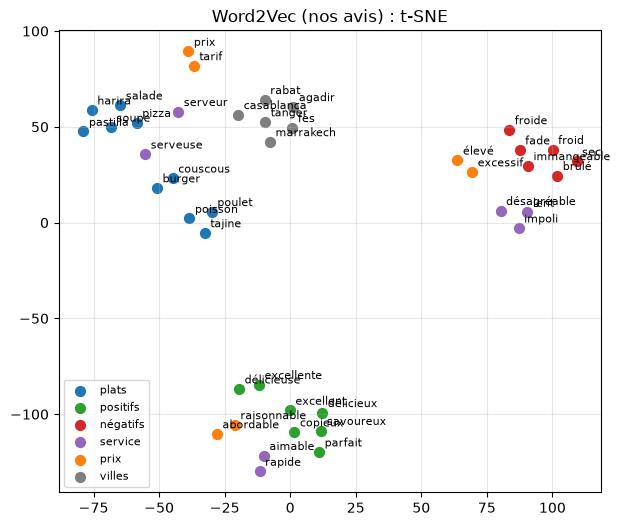

In [58]:
# À COMPLÉTER
def dessiner(ax, mots, cats, coords, titre):
    for cat, col in COULEURS.items():
        idx = [i for i, c in enumerate(cats) if c == cat]
        ax.scatter(coords[idx, 0], coords[idx, 1], color=col, label=cat, s=50)
    for m, (x, y) in zip(mots, coords):
        ax.annotate(m, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.set_title(titre)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig, ax = plt.subplots(figsize=(7, 6))
dessiner(ax, mots, cats, coords, "Word2Vec (nos avis) : t-SNE")
plt.show()

### Exercice 4.3 — La figure du livrable
Sur une même figure (1 ligne, 2 colonnes), dessinez la projection t-SNE de **notre Word2Vec** (à gauche) et de **FastText pré-entraîné** (à droite).
Enregistrez-la dans `tsne_tp7.png` (`plt.savefig(..., dpi=150)`).

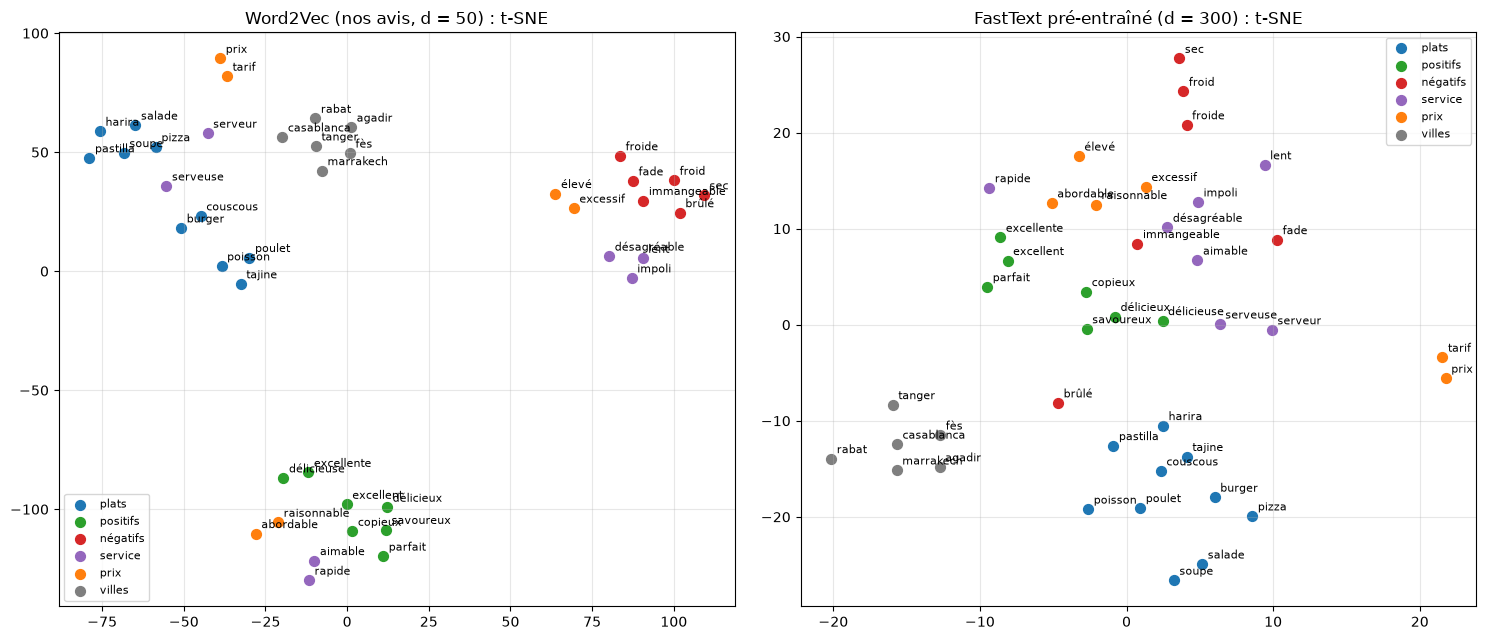

In [59]:
# À COMPLÉTER
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (nom, wv) in zip(axes, [("Word2Vec (nos avis, d = 50)", modele_sg.wv),
                                ("FastText pré-entraîné (d = 300)", ft_fr)]):
    m_, c_, xy = projeter(wv, CATEGORIES, "tsne")
    dessiner(ax, m_, c_, xy, nom + " : t-SNE")
plt.tight_layout()
plt.savefig("tsne_tp7.png", dpi=150)
plt.show()

In [60]:
# Test 4.3
import os
assert os.path.exists("tsne_tp7.png")
print("✅ Exercice 4.3 réussi : figure enregistrée")

✅ Exercice 4.3 réussi : figure enregistrée


### Exercice 4.4 — ACP ou t-SNE ?
Refaites la figure de **notre Word2Vec** avec `methode="pca"` à gauche et `methode="tsne"` à droite. Laquelle sépare le mieux les catégories ?

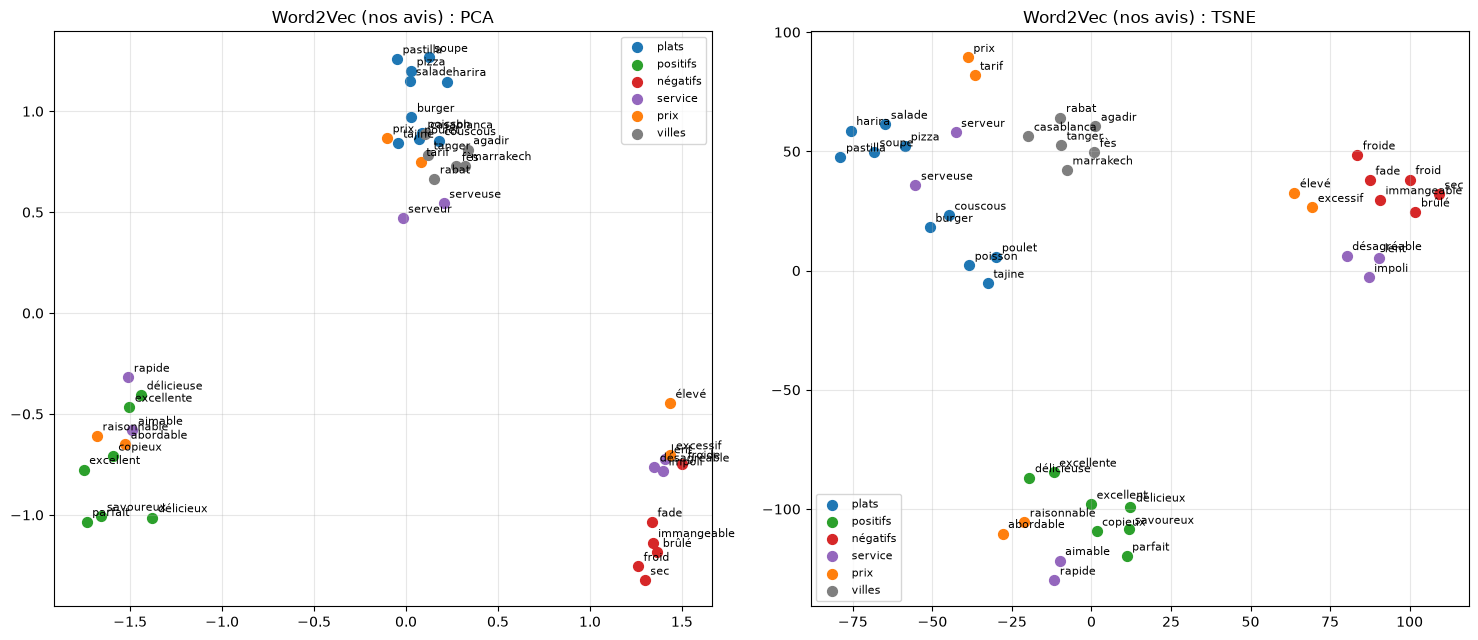

In [61]:
# À COMPLÉTER
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, methode in zip(axes, ["pca", "tsne"]):
    m_, c_, xy = projeter(modele_sg.wv, CATEGORIES, methode)
    dessiner(ax, m_, c_, xy, f"Word2Vec (nos avis) : {methode.upper()}")
plt.tight_layout()
plt.show()

## Partie 5 — Analyse (livrable)
Répondez en quelques phrases, en vous appuyant sur **vos** sorties et sur la figure `tsne_tp7.png`.

1. Quels **groupes** voyez-vous sur la figure de notre Word2Vec ? Sont-ils aussi nets sur la figure FastText pré-entraîné ? Où sont placés les adjectifs **féminins** (délicieuse, excellente, froide) ?
2. Les voisins d'un mot sont-ils toujours des **synonymes** ? Donnez un exemple tiré de vos résultats.
3. Pourquoi les **analogies** échouent-elles sur notre corpus, et réussissent-elles avec FastText pré-entraîné ?
4. Dans quel cas choisiriez-vous **FastText** plutôt que Word2Vec pour des avis marocains ? Justifiez avec l'exercice 3.7.
5. Citez une **limite** commune à Word2Vec et FastText (pensez à « froid » : un plat froid, une boisson froide, un accueil froid).

*Vos réponses :* (à vérifier et ajuster avec vos propres sorties et votre figure)

1. Sur notre Word2Vec, on voit des groupes assez nets pour les **villes**, les **plats** et les **prix**, plus flous pour les adjectifs (positifs/négatifs/service qui se mélangent parfois). Sur FastText pré-entraîné, les groupes sont plus nets et mieux séparés (positifs vs négatifs notamment). Les adjectifs **féminins** (délicieuse, excellente, froide) se placent près de leur forme masculine ou, dans notre modèle, de façon peu fiable parce qu'ils sont rares ; le sens domine la forme grammaticale.
2. Non. Les voisins sont des mots qui apparaissent dans des **contextes similaires**, pas forcément des synonymes : cela inclut des **antonymes** (rapide ~ lent, froid ~ chaud, qui s'emploient dans les mêmes phrases) et des mots associés (tajine ~ couscous, hyponymes/co-hyponymes).
3. Sur notre corpus, il y a trop peu de données (1 800 avis) : les vecteurs sont instables et les régularités (accord, pays/capitale) n'apparaissent pas. Les vecteurs pré-entraînés sont appris sur des milliards de mots, en dimension 300, ce qui fait émerger ces directions régulières.
4. FastText est préférable quand il y a beaucoup de **mots inconnus ou mal orthographiés** : fautes (« servuer »), allongements (« délicieuxxx »), variantes d'arabizi (« bzaf » / « bezaf »). Comme il s'appuie sur les n-grammes de caractères (ex. 3.7), il fournit un vecteur pour ces mots, alors que Word2Vec lève une `KeyError`.
5. Un seul vecteur par mot (**polysémie** ignorée) : « froid » (plat froid, boisson froide, accueil froid) a un vecteur unique qui mélange tous ses sens. Les vecteurs sont **statiques**, indépendants du contexte (et reproduisent les biais des données).

## Pour aller plus loin (pour les plus rapides)

### A. Le vecteur d'un avis entier
Une méthode simple pour représenter un **avis** : la **moyenne** des vecteurs de ses mots connus.
Écrivez `vecteur_avis(wv, texte)` puis trouvez, pour un avis requête, les 3 avis du corpus les plus proches (cosinus). C'est un petit moteur de recherche **sémantique** (comparez avec `search(query)` du TP6).

In [62]:
# À COMPLÉTER
def vecteur_avis(wv, texte):
    mots = [m for m in tokeniser(texte) if m in wv.key_to_index]
    if not mots:
        return np.zeros(wv.vector_size)
    return np.mean([wv[m] for m in mots], axis=0)

M = np.vstack([vecteur_avis(modele_sg.wv, t) for t in textes])
requete = "le plat est arrivé froid"
q = vecteur_avis(modele_sg.wv, requete)
scores = M @ q / (np.linalg.norm(M, axis=1) * np.linalg.norm(q) + 1e-9)   # un cosinus par avis
for i in np.argsort(-scores)[:3]:
    print(round(float(scores[i]), 3), "|", textes[i])

0.921 | Le poulet est super immangeable. Le serveur est vraiment désagréable. Dommage.
0.918 | Le couscous était super froid. Le service est désagréable. À éviter.
0.917 | Le serveur était super absent. Le poulet est immangeable. Dommage.


### B. Les biais des vecteurs pré-entraînés
Les vecteurs apprennent aussi les **stéréotypes** présents dans les textes du web. Testez :
`analogie(ft_fr, "médecin", "homme", "femme")` et `analogie(ft_fr, "ingénieur", "homme", "femme")`. Qu'observez-vous ?

In [63]:
# À COMPLÉTER
for metier in ["médecin", "ingénieur", "directeur"]:
    print(f"{metier} - homme + femme ->", analogie(ft_fr, metier, "homme", "femme"))

médecin - homme + femme -> [('pédiatre', 0.66), ('gynécologue', 0.65), ('infirmière', 0.64)]
ingénieur - homme + femme -> [('ingénieure', 0.73), ('Ingénieur', 0.67), ('diplômée', 0.56)]
directeur - homme + femme -> [('directrice', 0.79), ('Directrice', 0.73), ('vice-présidente', 0.69)]


### C. Influence des hyperparamètres
Refaites l'exercice 2.4 avec `window=1` puis `window=8`, `vector_size=10` puis `100`, `epochs=5`. Que deviennent les voisins de « tajine » ? La figure t-SNE ?

In [64]:
# Influence des hyperparamètres : voisins de « tajine »
configs = [dict(window=1), dict(window=8), dict(vector_size=10), dict(vector_size=100), dict(epochs=5)]
base = dict(vector_size=50, window=3, min_count=3, sg=1, epochs=30, seed=1, workers=1)
for cfg in configs:
    params = {**base, **cfg}
    mod = Word2Vec(phrases, **params)
    print(cfg, "->", voisins(mod.wv, "tajine", 5))

{'window': 1} -> [('poisson', 0.91), ('poulet', 0.88), ('tanjia', 0.62), ('couscous', 0.62), ('msemen', 0.61)]
{'window': 8} -> [('poulet', 0.83), ('poisson', 0.81), ('couscous', 0.66), ('msemen', 0.61), ('burger', 0.61)]
{'vector_size': 10} -> [('poulet', 0.98), ('poisson', 0.96), ('msemen', 0.93), ('sandwich', 0.9), ('couscous', 0.9)]
{'vector_size': 100} -> [('poisson', 0.87), ('poulet', 0.81), ('msemen', 0.62), ('burger', 0.56), ('sandwich', 0.54)]
{'epochs': 5} -> [('poulet', 0.98), ('poisson', 0.98), ('amandes', 0.97), ('pruneaux', 0.97), ('maison', 0.95)]
